# EuroSAT Land-Cover Classification — A Comparative Deep Learning Study with Transfer Learning

## Notebook 02 — Data Split & TensorFlow Pipeline

## Notebook Goal

Notebook 01 audited the raw dataset. This notebook turns it into something a model can actually train on:

- A **stratified** 80/10/10 train/validation/test split, so every class keeps roughly the same proportion in each subset instead of drifting by chance.
- A clean `tf.data.Dataset` pipeline that reads each image file, decodes it, and scales it to a `[0, 1]` float range.

The test set is created here so it exists for later, but it is **not used for any training, tuning, or comparison decision** in this or any notebook before Notebook 08 — it is only meant to be evaluated once, at the very end.

## Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split

## Configuration

In [ ]:
DATASET_ROOT = Path("data/EuroSAT_RGB")

CLASS_NAMES = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River",
    "SeaLake",
]

CLASS_TO_ID = {class_name: idx for idx, class_name in enumerate(CLASS_NAMES)}
EXPECTED_EXTENSIONS = {".jpg", ".jpeg"}

SEED = 42
IMAGE_SIZE = (64, 64)
NUM_CLASSES = 10
BATCH_SIZE = 32

tf.random.set_seed(SEED)
np.random.seed(SEED)

## Build the Manifest

We scan each class folder for actual JPEG image files (the same file-type check used in Notebook 01) and build one DataFrame with `filepath`, `class_name`, and an explicit integer `label` from `CLASS_TO_ID`.

In [3]:
records = []
for class_name in CLASS_NAMES:
    class_dir = DATASET_ROOT / class_name
    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in EXPECTED_EXTENSIONS:
            records.append((str(path), class_name, CLASS_TO_ID[class_name]))

manifest_df = pd.DataFrame(records, columns=["filepath", "class_name", "label"])

print(f"Manifest rows: {len(manifest_df)}")

assert manifest_df["class_name"].isin(CLASS_NAMES).all(), "Unexpected class label found."
assert manifest_df["class_name"].nunique() == NUM_CLASSES, "Unexpected number of classes."
assert manifest_df["filepath"].duplicated().sum() == 0, "Duplicate file paths found."

print(f"Unique classes: {manifest_df['class_name'].nunique()} (expected {NUM_CLASSES})")
print(f"Duplicate filepaths: {manifest_df['filepath'].duplicated().sum()}")

Manifest rows: 27000
Unique classes: 10 (expected 10)
Duplicate filepaths: 0


## Inspect Overall Class Distribution

A quick look at how many images each class has before any splitting happens.

In [4]:
distribution_df = (
    manifest_df.groupby(["class_name", "label"])
    .size()
    .reset_index(name="count")
    .sort_values("label")
    .reset_index(drop=True)
)
distribution_df["percentage"] = (distribution_df["count"] / len(manifest_df) * 100).round(2)

distribution_df

,class_name,label,count,percentage
0,AnnualCrop,0,3000,11.11
1,Forest,1,3000,11.11
2,HerbaceousVegetation,2,3000,11.11
3,Highway,3,2500,9.26
4,Industrial,4,2500,9.26
5,Pasture,5,2000,7.41
6,PermanentCrop,6,2500,9.26
7,Residential,7,3000,11.11
8,River,8,2500,9.26
9,SeaLake,9,3000,11.11


## Create the Stratified Split

A two-stage stratified split: first 80% train / 20% temporary, then the temporary 20% is split 50/50 into validation and test. Stratifying on `label` at each stage keeps class proportions consistent, giving an overall 80/10/10 split.

In [5]:
train_df, temp_df = train_test_split(
    manifest_df,
    test_size=0.20,
    stratify=manifest_df["label"],
    random_state=SEED,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train:      {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test:       {len(test_df)}")
print(f"Total:      {len(train_df) + len(val_df) + len(test_df)} (manifest: {len(manifest_df)})")

Train:      21600
Validation: 2700
Test:       2700
Total:      27000 (manifest: 27000)


## Verify the Split

We check that the split sizes add back up to the full manifest, and that class proportions were preserved across train/validation/test.

In [ ]:
assert len(train_df) + len(val_df) + len(test_df) == len(manifest_df)

def class_counts(df, name):
    return df["class_name"].value_counts().reindex(CLASS_NAMES).rename(name)

split_counts_df = pd.concat(
    [
        class_counts(train_df, "train"),
        class_counts(val_df, "val"),
        class_counts(test_df, "test"),
    ],
    axis=1,
)
split_counts_df["total"] = split_counts_df.sum(axis=1)

split_counts_df

,train,val,test,total
class_name,,,,
AnnualCrop,2400,300,300,3000
Forest,2400,300,300,3000
HerbaceousVegetation,2400,300,300,3000
Highway,2000,250,250,2500
Industrial,2000,250,250,2500
Pasture,1600,200,200,2000
PermanentCrop,2000,250,250,2500
Residential,2400,300,300,3000
River,2000,250,250,2500


## Check for Filepath Overlap

A simple set-intersection check confirms the same image file never appears in two different splits.

In [7]:
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

train_val_overlap = len(train_paths & val_paths)
train_test_overlap = len(train_paths & test_paths)
val_test_overlap = len(val_paths & test_paths)

print(f"Train/Validation overlap: {train_val_overlap}")
print(f"Train/Test overlap:       {train_test_overlap}")
print(f"Validation/Test overlap:  {val_test_overlap}")

assert train_val_overlap == 0
assert train_test_overlap == 0
assert val_test_overlap == 0

Train/Validation overlap: 0
Train/Test overlap:       0
Validation/Test overlap:  0


## Build the TensorFlow Image Loading Function

`load_image` reads a file, decodes it as JPEG, resizes it to `IMAGE_SIZE`, and scales pixel values from the original 0–255 range to 0–1 as `float32`. Neural networks generally train more smoothly on small, consistently-scaled inputs than on raw 0–255 integers. We're not applying any dataset-specific mean/std normalization here — that would be unnecessary complexity for this baseline pipeline. If a pretrained model later needs its own specific preprocessing, that will be handled explicitly in the Transfer Learning notebook rather than assumed here.

In [ ]:
def load_image(filepath, label):
    #Read a JPEG file, decode it, resize to IMAGE_SIZE, and scale pixels to [0, 1]
    image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

## Build tf.data Datasets

Each split becomes a `tf.data.Dataset` of `(filepath, label)` pairs, mapped through `load_image`, batched, and prefetched. Only the training dataset is shuffled: shuffling validation or test wouldn't change how they're used, and keeping them in a fixed order makes runs easier to inspect and reproduce.

In [9]:
def make_dataset(df, shuffle, seed=SEED, batch_size=BATCH_SIZE):
    filepaths = df["filepath"].values
    labels = df["label"].values

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=seed, reshuffle_each_iteration=True)

    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, shuffle=True)
val_ds = make_dataset(val_df, shuffle=False)
test_ds = make_dataset(test_df, shuffle=False)

print("train_ds:", train_ds)
print("val_ds:  ", val_ds)
print("test_ds: ", test_ds)

train_ds: <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
val_ds:   <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>
test_ds:  <_PrefetchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


## Verify the TensorFlow Pipeline

We pull a single batch from `train_ds` only — as a technical sanity check, not a modeling decision — and inspect its shape, dtype, and value range.

In [10]:
images, labels = next(iter(train_ds))

print(f"Image batch shape: {images.shape}")
print(f"Label batch shape: {labels.shape}")
print(f"Image dtype: {images.dtype}")
print(f"Label dtype: {labels.dtype}")
print(f"Min pixel value: {tf.reduce_min(images).numpy():.4f}")
print(f"Max pixel value: {tf.reduce_max(images).numpy():.4f}")
print(f"First few labels: {labels.numpy()[:8]}")

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>
Min pixel value: 0.0980
Max pixel value: 1.0000
First few labels: [7 3 3 9 9 0 2 8]


## One Simple Pipeline Visualization

A 3×3 grid of images from a training batch, labeled with their class name, just to confirm images decode correctly, labels line up with images, and scaling didn't visually break anything.

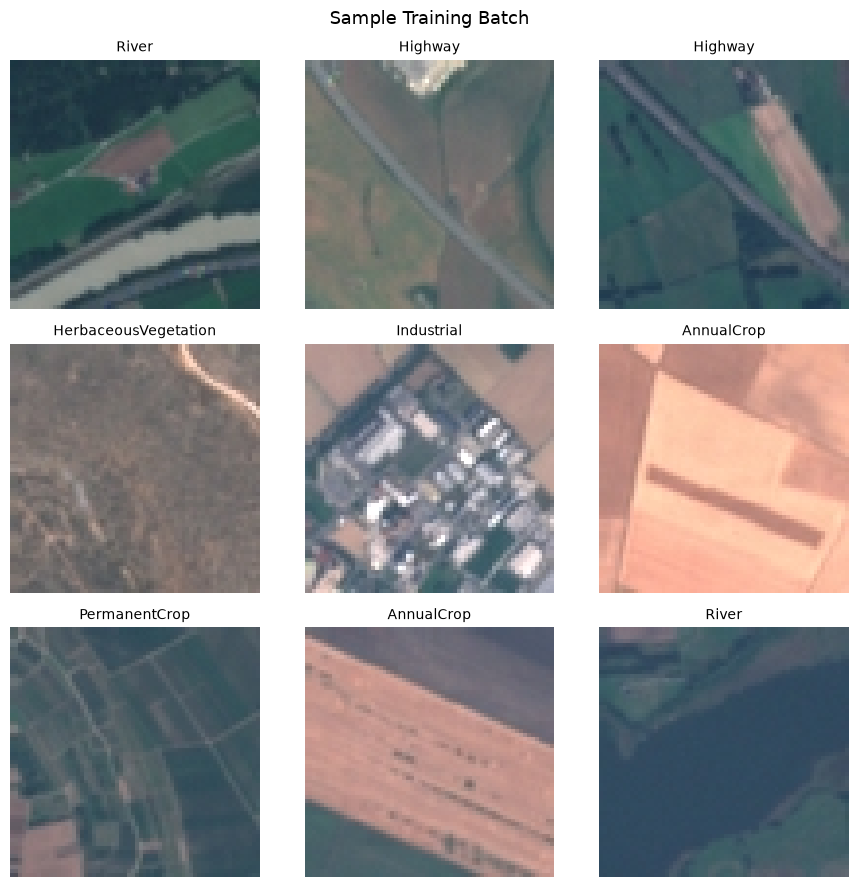

In [11]:
images, labels = next(iter(train_ds))

plt.figure(figsize=(9, 9))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy())
    plt.title(CLASS_NAMES[labels[i].numpy()], fontsize=10)
    plt.axis("off")

plt.suptitle("Sample Training Batch", fontsize=13)
plt.tight_layout()
plt.show()

## Why NHWC?

TensorFlow/Keras represents image batches as `(batch, height, width, channels)` — for this project, `(32, 64, 64, 3)`. That's different from PyTorch's typical `(batch, channels, height, width)` layout. Same image data either way — just the channel dimension sits in a different place, which is worth keeping in mind coming from PyTorch.

## Final Pipeline Summary

In [ ]:
print("Dataset -> Stratified Split -> TensorFlow Pipeline")
print("=" * 55)
print(f"Total images in manifest: {len(manifest_df)}")
print(f"Train:      {len(train_df)} ({len(train_df) / len(manifest_df):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df) / len(manifest_df):.1%})")
print(f"Test:       {len(test_df)} ({len(test_df) / len(manifest_df):.1%})")
print(f"Image size: {IMAGE_SIZE}, channels: 3, dtype: float32, pixel range: [0, 1]")
print(f"Batch size: {BATCH_SIZE}")
print("Test set is reserved for Notebook 08 and has not been used for any modeling decision here")

Dataset -> Stratified Split -> TensorFlow Pipeline
Total images in manifest: 27000
Train:      21600 (80.0%)
Validation: 2700 (10.0%)
Test:       2700 (10.0%)
Image size: (64, 64), channels: 3, dtype: float32, pixel range: [0, 1]
Batch size: 32
Test set is reserved for Notebook 08 and has not been used for any modeling decision here.


## Key Takeaways

- **Split:** the stratified two-stage split (`SEED = 42`) produced 21,600 train / 2,700 validation / 2,700 test images, i.e. exactly 80.0% / 10.0% / 10.0% of the 27,000 images.
- **Class proportions:** every class keeps the same proportion in all three subsets (for example AnnualCrop 2,400 / 300 / 300 and Pasture 1,600 / 200 / 200).
- **No overlap:** the filepath overlap check found 0 shared files between train/validation, train/test, and validation/test.
- **Pipeline:** the inspected training batch had shape `(32, 64, 64, 3)` with dtype `float32`, integer labels of shape `(32,)`, and pixel values within `[0, 1]` (that batch's minimum was 0.0980 and maximum 1.0000; the minimum is a property of that batch, not of the dataset).
- **Test set:** it was created here (and a `test_ds` object was built for completeness) but never iterated over, evaluated, or used for any modeling decision. It stays reserved for Notebook 08.

Everything came out as expected.
